### (2) 데이터 소개

#### 1) 기본 데이터

* 학습 데이터
    * air_2021.csv : 2021년 미세먼지 데이터
    * weather_2021.csv : 2021년 날씨 데이터
* 테스트 데이터
    * air_2022.csv : 2022년 미세먼지 데이터
    * weather_2022.csv : 2022년 날씨 데이터

#### 2) 데이터셋의 변수 소개(weather_2021)

* 증기압: 증기가 고체 또는 액체와 동적 평형 상태에 있을 때 증기의 압력 (증기가 되려는 힘)
* 이슬점 온도: 불포화 상태의 공기가 냉각될 때, 포화 상태에 도달하여 수증기의 응결이 시작되는 온도
* 일조: 일정한 물체나 땅의 겉면에 태양 광선이 비치는 시간 (1시간 중 비율)
* 일사(량): 태양으로부터 오는 태양 복사 에너지가 지표에 닿는 양 (면적당 에너지 량)
* 전운량: 하늘을 육안으로 관측하여 전부 구름일 때 10, 구름이 덮고 있는 하늘의 비율에 따라 0~10
* 중하층운량: 중층과 하층에 있는 구름의 분포량(중하층 구름이 날씨에 영향 주므로 따로 표기)
* 운형(운형약어): 구름의 종류. 약어 코드로 기재됨
* 최저운고: 가장 낮은 구름의 높이
* 현상번호(국내식): 비, 소낙비, 싸락눈, 눈보라 등의 기상현상을 나타낸 코드번호
* 지면온도: 지면 0cm 온도
* 지중온도: 땅 속 온도변수1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

# 필요한 라이브러리

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor as DTR
from sklearn.ensemble import RandomForestRegressor as RFR
from sklearn.ensemble import GradientBoostingRegressor as GBR
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import r2_score
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score as acc
from sklearn.metrics import recall_score as recall

import joblib

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [ ]:
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

## 필요한 함수

In [ ]:
def vif(dataframe, features):
    """
    다중공선성(VIF)을 계산하는 함수 (const 자동 제거)

    Parameters:
    - dataframe: pd.DataFrame
        입력 데이터프레임
    - features: list of str
        독립 변수(컬럼명) 리스트

    Returns:
    - vif_df: pd.DataFrame
        독립 변수들과 해당하는 VIF 값을 담은 데이터프레임
        (const는 포함되지 않음)
    """
    X = dataframe[features]
    X_const = add_constant(X)

    vif_data = pd.DataFrame()
    vif_data["변수"] = X_const.columns
    vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

    # const 행 제거
    vif_data = vif_data[vif_data["변수"] != "const"]

    return vif_data

In [ ]:
import statsmodels.api as sm
import pandas as pd
import matplotlib.pyplot as plt
import warnings

def stepwise_feature_selection(X_train, y_train, variables=None, sl_enter=0.05, sl_remove=0.05):
    """
    전진 선택 + 후진 제거를 통한 변수 선택

    Parameters:
    - X_train: pd.DataFrame
    - y_train: pd.Series 또는 np.array
    - variables: 선택에 사용할 변수 리스트 (기본: X_train.columns)
    - sl_enter: 포함 기준 p-value
    - sl_remove: 제거 기준 p-value

    Returns:
    - selected_variables: 최종 선택된 변수 리스트
    """
    warnings.filterwarnings("ignore")

    if variables is None:
        variables = X_train.columns.tolist()

    y = y_train.copy()
    selected_variables = []
    steps = []
    sv_per_step = []
    adjusted_r_squared = []
    step = 0

    while len(variables) > 0:
        remainder = list(set(variables) - set(selected_variables))
        pval = pd.Series(index=remainder, dtype=float)

        # 전진 선택
        for col in remainder:
            X = sm.add_constant(X_train[selected_variables + [col]])
            model = sm.OLS(y, X).fit()
            pval[col] = model.pvalues[col]

        min_pval = pval.min()

        if min_pval < sl_enter:
            best_var = pval.idxmin()
            selected_variables.append(best_var)

            # 후진 제거
            while len(selected_variables) > 0:
                X_selected = sm.add_constant(X_train[selected_variables])
                model = sm.OLS(y, X_selected).fit()
                selected_pvals = model.pvalues.drop('const')

                max_pval = selected_pvals.max()
                if max_pval >= sl_remove:
                    worst_var = selected_pvals.idxmax()
                    selected_variables.remove(worst_var)
                else:
                    break

            # 결과 저장
            step += 1
            steps.append(step)
            sv_per_step.append(selected_variables.copy())
            adj_r2 = sm.OLS(y, sm.add_constant(X_train[selected_variables])).fit().rsquared_adj
            adjusted_r_squared.append(adj_r2)

        else:
            break

    # 그래프 출력
    plt.figure(figsize=(12, 6))
    plt.xticks(steps, [f'Step {s}\n' + '\n'.join(sv) for s, sv in zip(steps, sv_per_step)], fontsize=10)
    plt.plot(steps, adjusted_r_squared, marker='o', color='blue')
    plt.ylabel('Adjusted R Squared', fontsize=12)
    plt.xlabel('Step', fontsize=12)
    plt.title('Stepwise Feature Selection Progress', fontsize=14)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return selected_variables

# [1] 데이터 셋 불러오기

In [ ]:
df_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/10주차/df_21.csv')
df_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/10주차/df_22.csv')

In [ ]:
df_21.head(3)

,time,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),...,지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),month,day,hour,PM10_lag1,PM10_1
0,2021-01-01 01:00:00,서울 종로구,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,...,-6.9,-1.0,-0.8,0.3,1.6,1,1,1,NaN,25.0
1,2021-01-01 02:00:00,서울 종로구,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,...,-7.1,-1.1,-0.8,0.3,1.6,1,1,2,NaN,27.0
2,2021-01-01 03:00:00,서울 종로구,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,...,-7.3,-1.2,-0.9,0.3,1.6,1,1,3,NaN,23.0


In [ ]:
df_22.head(3)

,time,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),...,지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),month,day,hour,PM10_lag1,PM10_1
0,2022-01-01 00:00:00,서울 종로구,0.003,0.4,0.026,0.016,20.0,9.0,-8.5,0.0,...,-7.0,-1.0,-1.0,-0.2,1.0,1,1,0,NaN,23.0
1,2022-01-01 01:00:00,서울 종로구,0.003,0.4,0.026,0.016,23.0,12.0,-9.2,0.0,...,-7.2,-1.1,-1.1,-0.2,1.0,1,1,1,NaN,20.0
2,2022-01-01 02:00:00,서울 종로구,0.003,0.4,0.022,0.020,20.0,9.0,-9.5,0.0,...,-7.5,-1.3,-1.2,-0.2,1.0,1,1,2,NaN,20.0


In [ ]:
# df_21, df_22에 t+1 시점(다음날) 변수(PM10_1) 추가
df_21['PM10_future']= df_21['PM10'].shift(-1)
#df_22['PM10_future']= df_22['PM10'].shift(-1)

In [ ]:
df_21.columns

Index(['time', '지역', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)',
       '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
       '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
       '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
       '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)',
       'month', 'day', 'hour', 'PM10_lag1', 'PM10_1', 'PM10_future'],
      dtype='object')

In [ ]:
df_21[['time', 'PM10', 'PM10_future']]

,time,PM10,PM10_future
0,2021-01-01 01:00:00,24.0,25.0
1,2021-01-01 02:00:00,25.0,27.0
2,2021-01-01 03:00:00,27.0,23.0
3,2021-01-01 04:00:00,23.0,24.0
4,2021-01-01 05:00:00,24.0,26.0
...,...,...,...
8754,2021-12-31 19:00:00,25.0,26.0
8755,2021-12-31 20:00:00,26.0,27.0
8756,2021-12-31 21:00:00,27.0,20.0
8757,2021-12-31 22:00:00,20.0,20.0


In [ ]:
temp_corr = df_21[['CO', '풍향(16방위)', '습도(%)', '시정(10m)', '전운량(10분위)', 'PM10_future']].corr()

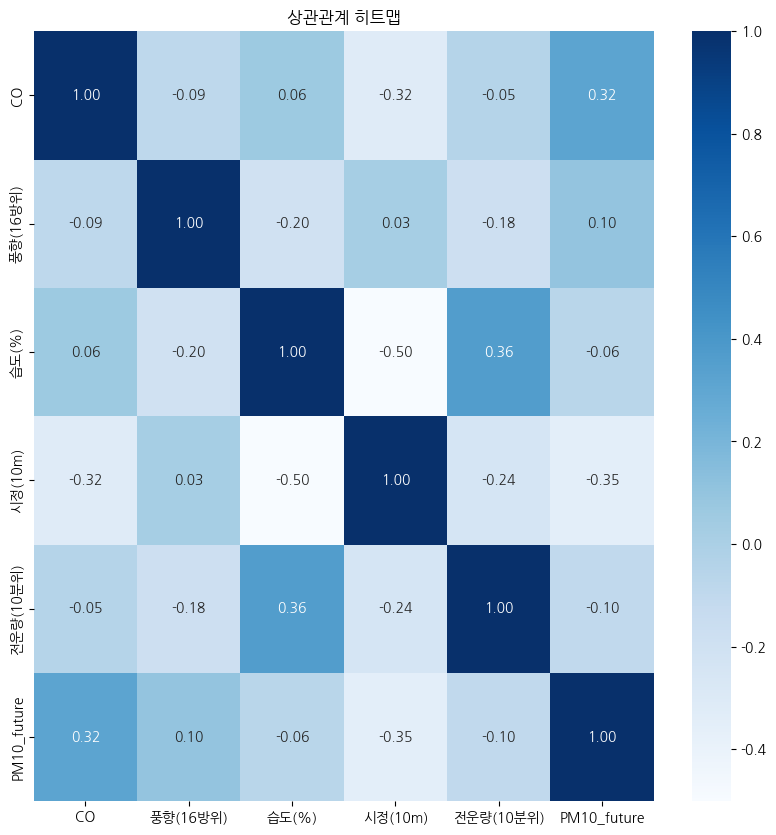

In [ ]:
plt.figure(figsize=(10, 10))
sns.heatmap(temp_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("상관관계 히트맵")
plt.show()

# [2] 다중공선성 확인 및 단계별 선택법 적용

================================================================================

In [ ]:
temp_21 = df_21.rename(columns={
    '기온(°C)': '기온',
    '강수량(mm)': '강수량',
    '풍속(m/s)': '풍속',
    '풍향(16방위)': '풍향',
    '습도(%)': '습도',
    '증기압(hPa)': '증기압',
    '이슬점온도(°C)': '이슬점온도',
    '현지기압(hPa)': '현지기압',
    '해면기압(hPa)': '해면기압',
    '일조(hr)': '일조',
    '일사(MJ/m2)': '일사',
    '적설(cm)': '적설',
    '3시간신적설(cm)': '시간3신적설',
    '전운량(10분위)': '전운량',
    '중하층운량(10분위)': '중하층운량',
    '최저운고(100m )': '최저운고',
    '시정(10m)': '시정',
    '지면온도(°C)': '지면온도',
    '5cm 지중온도(°C)': '지중온도5',
    '10cm 지중온도(°C)': '지중온도10',
    '20cm 지중온도(°C)': '지중온도20',
    '30cm 지중온도(°C)': '지중온도30',
    'PM10_1': 'PM10_1'
})

In [ ]:
import statsmodels.api as sm

# 제외할 열
exclude_cols = ['time', '지역', 'month', 'day', 'hour', 'PM10_lag1', 'PM10', 'PM25', 'PM10_future', 'PM10_1']

# 사용 가능한 독립 변수 목록 추출
independent_vars = [col for col in temp_21.columns if col not in exclude_cols]

# formula 문자열 만들기
formula = "PM10_1 ~ " + " + ".join(independent_vars)

# 회귀 모델 생성 및 학습
model = sm.OLS.from_formula(formula, data=temp_21)
result = model.fit()

# 요약 출력
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                 PM10_1   R-squared:                       0.319
Model:                            OLS   Adj. R-squared:                  0.316
Method:                 Least Squares   F-statistic:                     156.9
Date:                Thu, 08 May 2025   Prob (F-statistic):               0.00
Time:                        14:01:26   Log-Likelihood:                -44514.
No. Observations:                8758   AIC:                         8.908e+04
Df Residuals:                    8731   BIC:                         8.927e+04
Df Model:                          26                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1499.9803     92.628     16.194      0.0

In [ ]:
vif(temp_21, independent_vars)

,변수,VIF
1,SO2,1.465439
2,CO,5.544960
3,O3,3.968285
4,NO2,6.629391
5,기온,433.077599
6,강수량,1.343252
7,풍속,1.563800
8,풍향,1.312995
9,습도,53.179050
10,증기압,15.292935


In [ ]:
temp_21 = temp_21.dropna()
temp_21

,time,지역,SO2,CO,O3,NO2,PM10,PM25,기온,강수량,...,지중온도5,지중온도10,지중온도20,지중온도30,month,day,hour,PM10_lag1,PM10_1,PM10_future
24,2021-01-02 01:00:00,서울 종로구,0.003,0.4,0.032,0.009,32.0,15.0,-4.1,0.0,...,-0.2,-0.5,0.1,1.3,1,2,1,24.0,25.0,25.0
25,2021-01-02 02:00:00,서울 종로구,0.003,0.4,0.031,0.010,25.0,9.0,-5.0,0.0,...,-0.4,-0.6,0.1,1.3,1,2,2,25.0,29.0,29.0
26,2021-01-02 03:00:00,서울 종로구,0.003,0.4,0.017,0.022,29.0,12.0,-5.8,0.0,...,-0.5,-0.7,0.1,1.3,1,2,3,27.0,24.0,24.0
27,2021-01-02 04:00:00,서울 종로구,0.002,0.4,0.027,0.014,24.0,13.0,-6.3,0.0,...,-0.7,-0.8,0.0,1.3,1,2,4,23.0,20.0,20.0
28,2021-01-02 05:00:00,서울 종로구,0.003,0.4,0.031,0.010,20.0,8.0,-6.6,0.0,...,-0.9,-0.9,0.0,1.3,1,2,5,24.0,19.0,19.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8753,2021-12-31 18:00:00,서울 종로구,0.003,0.4,0.029,0.018,24.0,9.0,-5.9,0.0,...,-0.3,-0.6,-0.1,1.0,12,31,18,26.0,25.0,25.0
8754,2021-12-31 19:00:00,서울 종로구,0.003,0.4,0.026,0.019,25.0,10.0,-6.4,0.0,...,-0.5,-0.7,-0.1,1.0,12,31,19,23.0,26.0,26.0
8755,2021-12-31 20:00:00,서울 종로구,0.003,0.4,0.025,0.020,26.0,8.0,-6.3,0.0,...,-0.6,-0.8,-0.1,1.0,12,31,20,24.0,27.0,27.0
8756,2021-12-31 21:00:00,서울 종로구,0.003,0.4,0.030,0.014,27.0,9.0,-6.7,0.0,...,-0.7,-0.8,-0.1,1.0,12,31,21,31.0,20.0,20.0


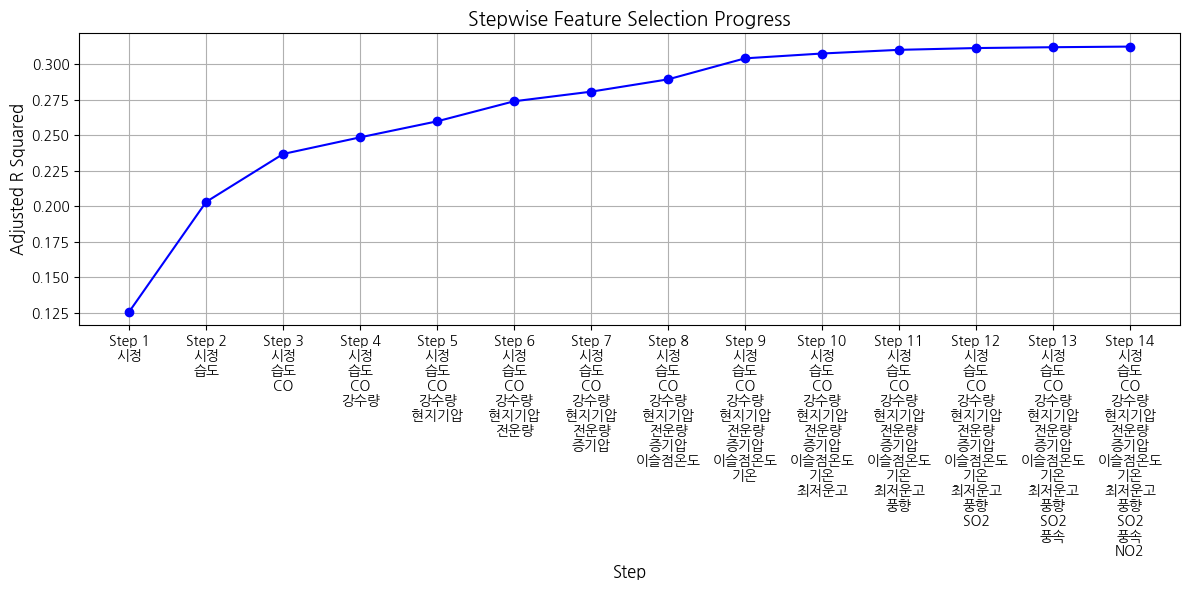

In [ ]:
selected_variables = stepwise_feature_selection(temp_21[independent_vars], temp_21['PM10_1'])

In [ ]:
vif(temp_21, selected_variables)

,변수,VIF
1,시정,1.949866
2,습도,49.206527
3,CO,4.875432
4,강수량,1.116716
5,현지기압,2.508785
6,전운량,1.897035
7,증기압,11.636185
8,이슬점온도,339.591523
9,기온,233.510969
10,최저운고,1.871106


================================================================================

In [ ]:
df_21.columns

Index(['time', '지역', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)',
       '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
       '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
       '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
       '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)',
       'month', 'day', 'hour', 'PM10_lag1', 'PM10_1', 'PM10_future'],
      dtype='object')

In [ ]:
vif(df_21, ['지면온도(°C)', '30cm 지중온도(°C)','증기압(hPa)'])

,변수,VIF
1,지면온도(°C),4.127207
2,30cm 지중온도(°C),7.755137
3,증기압(hPa),6.277863


In [ ]:
col_list = ['SO2', 'CO', 'O3', 'NO2',
       '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)',
       '현지기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
       '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)', '30cm 지중온도(°C)']

In [ ]:
df_21_corr = df_21[col_list].corr()

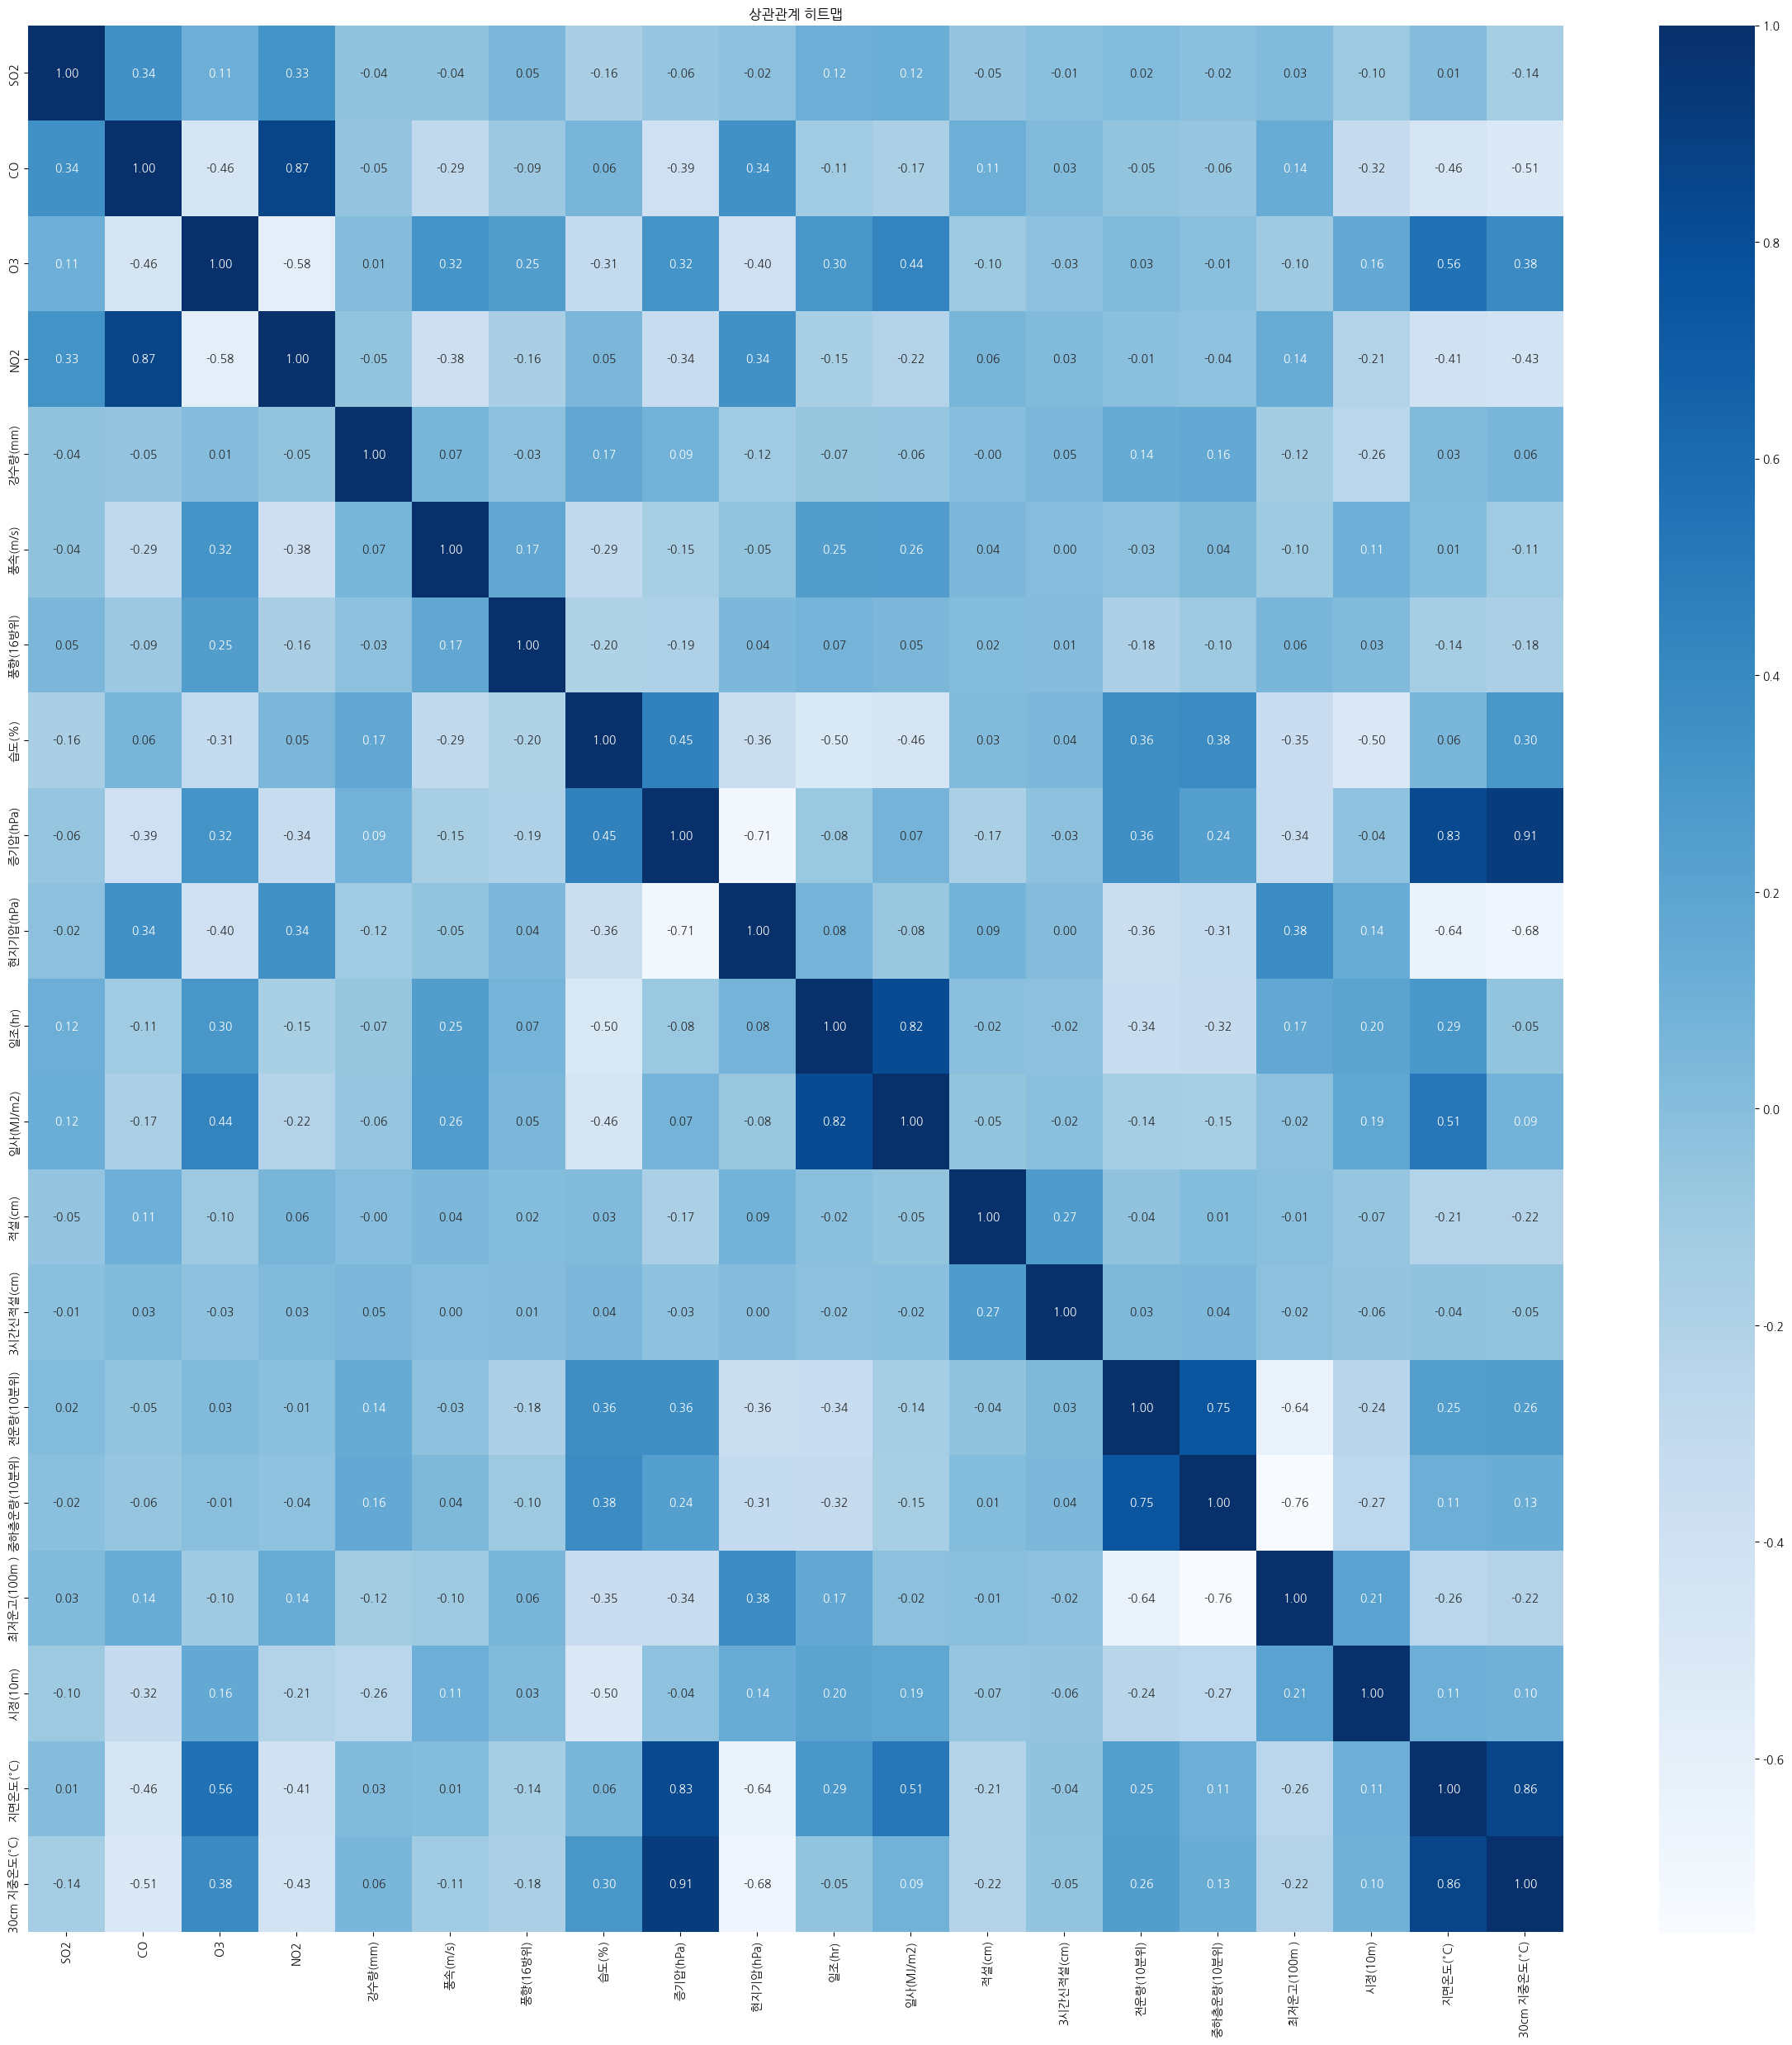

In [ ]:
plt.figure(figsize=(30, 30))
sns.heatmap(df_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("상관관계 히트맵")
plt.show()

In [ ]:
selected_features_final = col_list

In [ ]:
df_21_corr = df_21[selected_features_final].corr()


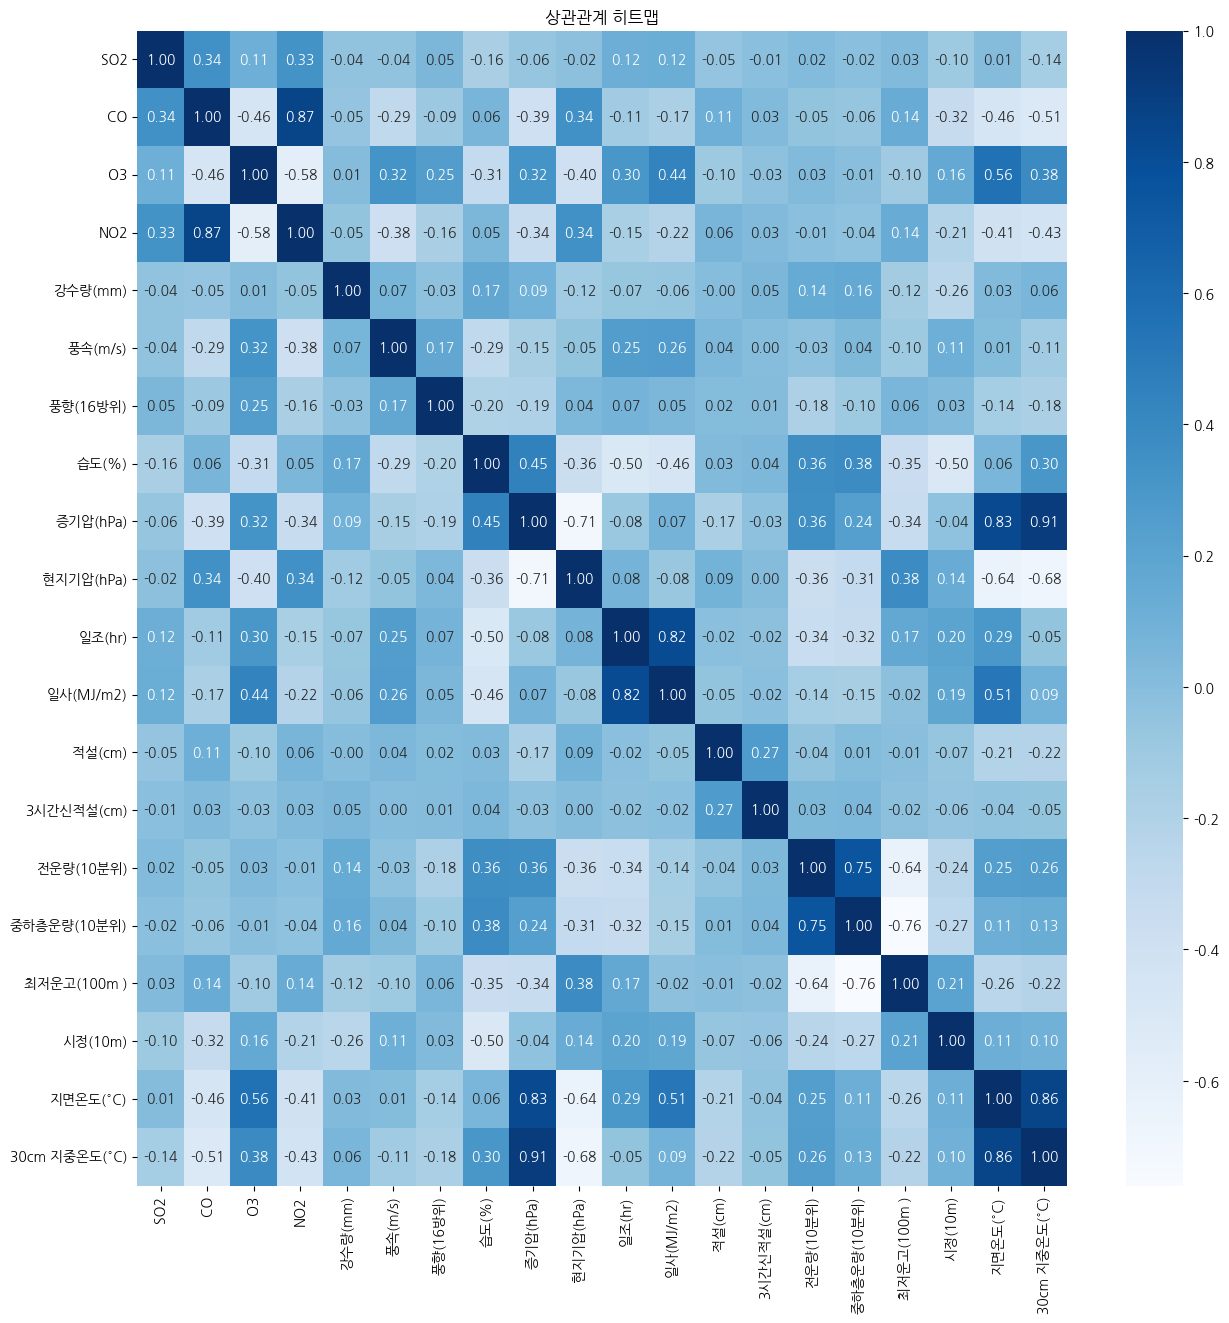

In [ ]:
plt.figure(figsize=(15, 15))
sns.heatmap(df_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("상관관계 히트맵")
plt.show()

In [ ]:
selected_features_final

['SO2',
 'CO',
 'O3',
 'NO2',
 '강수량(mm)',
 '풍속(m/s)',
 '풍향(16방위)',
 '습도(%)',
 '증기압(hPa)',
 '현지기압(hPa)',
 '일조(hr)',
 '일사(MJ/m2)',
 '적설(cm)',
 '3시간신적설(cm)',
 '전운량(10분위)',
 '중하층운량(10분위)',
 '최저운고(100m )',
 '시정(10m)',
 '지면온도(°C)',
 '30cm 지중온도(°C)']

In [ ]:
df_21.columns

Index(['time', '지역', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)',
       '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
       '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
       '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
       '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)',
       'month', 'day', 'hour', 'PM10_lag1', 'PM10_1', 'PM10_future'],
      dtype='object')

# [4] 모델 훈련 및 테스트

## 4-1. 전체 데이터로 돌려보기

#### X, y 설정

In [ ]:
df_21.columns

Index(['time', '지역', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)',
       '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
       '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
       '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
       '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)',
       'month', 'day', 'hour', 'PM10_lag1', 'PM10_1', 'PM10_future'],
      dtype='object')

In [ ]:
df_21 = df_21.dropna()
df_22 = df_22.dropna()

In [ ]:
X_train = df_21[[ 'SO2', 'CO', 'O3', 'NO2', '기온(°C)',
                  '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                  '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
                  '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
                  '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']].values
X_test = df_22[[ 'SO2', 'CO', 'O3', 'NO2', '기온(°C)',
                 '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                 '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
                 '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
                 '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']].values

y_train = df_21['PM10_1']
y_test = df_22['PM10_1']

In [ ]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

### LinearRegression

In [ ]:
regressor = LinearRegression()
regressor.fit(X_train_sc, y_train)

LinearRegression()

In [ ]:
y_pred = regressor.predict(X_test_sc)

In [ ]:
y_pred

array([56.22467645, 31.78639135, 30.96979556, ..., 42.35176612,
       37.76080771, 20.65276056])

In [ ]:
y_test

,PM10_1
24,38.0
25,34.0
26,35.0
27,33.0
28,33.0
...,...
2154,10.0
2155,11.0
2156,10.0
2157,11.0


In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

18.08367129872073


In [ ]:
r2_score(y_test, y_pred)

0.41210004115491894

### 랜덤포레스트

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

In [ ]:
rf_model = RFR(random_state=42)

In [ ]:
grid_search = GridSearchCV(estimator=rf_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

In [ ]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [10, 20, None],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='neg_mean_squared_error', verbose=1)

In [ ]:
best_params = grid_search.best_params_

In [ ]:
rf_model = RFR(**best_params, random_state=42)

In [ ]:
rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, min_samples_leaf=2, random_state=42)

In [ ]:
y_pred = rf_model.predict(X_test)

In [ ]:
y_test

,PM10_1
24,38.0
25,34.0
26,35.0
27,33.0
28,33.0
...,...
2154,10.0
2155,11.0
2156,10.0
2157,11.0


In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

14.135392033438094


In [ ]:
r2_score(y_test, y_pred)

0.6407920527660165

### XGBRegressor

In [ ]:
# XGBoost 모델 정의
xgb_model = XGBRegressor(random_state=42)

# 그리드 서치에서 탐색할 하이퍼파라미터 정의
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# 그리드 서치 수행
grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None,
                                    random_state=42, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [3, 4, 5], 'n_estimators': [50, 100, 200],
                         'subsample': [0.8, 1.0]},
             scoring='neg_mean_squared_error', verbose=1)

In [ ]:
grid_search.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.2,
 'max_depth': 4,
 'n_estimators': 50,
 'subsample': 1.0}

In [ ]:
xgb_model = grid_search.best_estimator_

In [ ]:
# 4. 예측
y_pred = xgb_model.predict(X_test)

# 5. 성능 평가
print(np.sqrt(mse(y_test, y_pred)))

15.532617217896497


In [ ]:
r2_score(y_test, y_pred)

0.5632405795386795

## 4-2. 일부 변수만 선택해서 모델 훈련

#### X, y 설정

In [ ]:
selected_features_final

['SO2',
 'CO',
 'O3',
 'NO2',
 '강수량(mm)',
 '풍속(m/s)',
 '풍향(16방위)',
 '습도(%)',
 '증기압(hPa)',
 '현지기압(hPa)',
 '일조(hr)',
 '일사(MJ/m2)',
 '적설(cm)',
 '3시간신적설(cm)',
 '전운량(10분위)',
 '중하층운량(10분위)',
 '최저운고(100m )',
 '시정(10m)',
 '지면온도(°C)',
 '30cm 지중온도(°C)']

In [ ]:
X_train = df_21[selected_features_final].values
X_test = df_22[selected_features_final].values

In [ ]:
X_train

array([[ 3.0e-03,  4.0e-01,  3.2e-02, ...,  2.0e+03, -4.7e+00,  1.3e+00],
       [ 3.0e-03,  4.0e-01,  3.1e-02, ...,  2.0e+03, -5.3e+00,  1.3e+00],
       [ 3.0e-03,  4.0e-01,  1.7e-02, ...,  2.0e+03, -5.9e+00,  1.3e+00],
       ...,
       [ 3.0e-03,  4.0e-01,  2.5e-02, ...,  2.0e+03, -5.3e+00,  1.0e+00],
       [ 3.0e-03,  4.0e-01,  3.0e-02, ...,  2.0e+03, -5.7e+00,  1.0e+00],
       [ 3.0e-03,  4.0e-01,  3.3e-02, ...,  2.0e+03, -6.2e+00,  1.0e+00]])

In [ ]:
X_test

array([[ 5.00e-03,  1.20e+00,  2.00e-03, ...,  2.00e+03, -3.30e+00,
         8.00e-01],
       [ 4.00e-03,  8.00e-01,  2.00e-03, ...,  2.00e+03, -3.40e+00,
         8.00e-01],
       [ 4.00e-03,  8.00e-01,  2.00e-03, ...,  2.00e+03, -2.50e+00,
         8.00e-01],
       ...,
       [ 2.00e-03,  4.00e-01,  3.60e-02, ...,  2.00e+03,  8.90e+00,
         1.03e+01],
       [ 2.00e-03,  4.00e-01,  3.20e-02, ...,  2.00e+03,  7.80e+00,
         1.04e+01],
       [ 3.00e-03,  3.00e-01,  3.80e-02, ...,  2.00e+03,  7.30e+00,
         1.05e+01]])

In [ ]:
y_train = df_21['PM10_1']
y_test = df_22['PM10_1']
y_train

,PM10_1
24,25.0
25,29.0
26,24.0
27,20.0
28,19.0
...,...
8753,25.0
8754,26.0
8755,27.0
8756,20.0


In [ ]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

### LinearRegression

In [ ]:
regressor = LinearRegression()
regressor.fit(X_train_sc, y_train)

LinearRegression()

In [ ]:
y_pred = regressor.predict(X_test_sc)

In [ ]:
y_pred

array([60.49575588, 32.27212501, 31.93977972, ..., 31.76981547,
       27.68864283,  8.64009769])

In [ ]:
y_test

,PM10_1
24,38.0
25,34.0
26,35.0
27,33.0
28,33.0
...,...
2154,10.0
2155,11.0
2156,10.0
2157,11.0


In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

17.975431686340368


In [ ]:
r2_score(y_test, y_pred)

0.4191167162677871

### 랜덤포레스트

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

rf_model = RFR(random_state=42)

grid_search = GridSearchCV(estimator=rf_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

In [ ]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [10, 20, None],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='neg_mean_squared_error', verbose=1)

In [ ]:
best_params = grid_search.best_params_

In [ ]:
rf_model = RFR(**best_params, random_state=42)

In [ ]:
rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=20, min_samples_leaf=2, min_samples_split=5,
                      random_state=42)

In [ ]:
y_pred = rf_model.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

14.255804094390601


In [ ]:
r2_score(y_test, y_pred)

0.6346461752521794

### XGBRegressor

In [ ]:
# XGBoost 모델 정의
xgb_model = XGBRegressor(random_state=42)

# 그리드 서치에서 탐색할 하이퍼파라미터 정의
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# 그리드 서치 수행
grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None,
                                    random_state=42, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [3, 4, 5], 'n_estimators': [50, 100, 200],
                         'subsample': [0.8, 1.0]},
             scoring='neg_mean_squared_error', verbose=1)

In [ ]:
best_params = grid_search.best_params_

In [ ]:
XGB_model = XGBRegressor(**best_params, random_state=42)

In [ ]:
XGB_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=100, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [ ]:
# 4. 예측
y_pred = XGB_model.predict(X_test)

# 5. 성능 평가
print(np.sqrt(mse(y_test, y_pred)))

20.07413404090714


In [ ]:
r2_score(y_test, y_pred)

0.2755576003539767

In [ ]:
y_pred

array([45.65921 , 42.07286 , 42.07286 , ..., 36.86904 , 25.089033,
       19.363499], dtype=float32)

In [ ]:
y_test.values

array([38., 34., 35., ..., 10., 11., 11.])